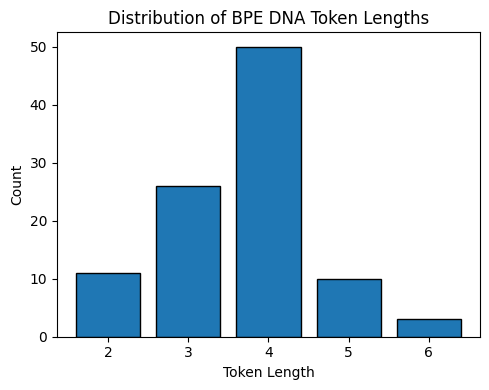

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

# Path to your file
filename = "../../data/tokenizers/clinvar_allele_bpe/selected_bpe_dna_tokens.txt"

# Read tokens and compute lengths
with open(filename, "r") as f:
    lengths = [
        len(line.strip())
        for line in f
        if line.strip()  # skip empty lines
    ]

# Count occurrences of each length
length_counts = Counter(lengths)

# Sort by token length
x = sorted(length_counts.keys())
y = [length_counts[length] for length in x]

# Plot
plt.figure(figsize=(6, 4))
plt.bar(x, y, width=0.8, edgecolor="black")
plt.xlabel("Token Length")
plt.ylabel("Count")
plt.title("Distribution of BPE DNA Token Lengths")
plt.xticks(x)
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd

df = pd.read_csv(
        "../../resources/variant_summary.txt.gz",
        sep="\t",
        compression="gzip",
    )
df

/var/folders/57/yk3w62md44z9m6ndy61mkkz80000gn/T/ipykernel_3000/2094544161.py:3: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),...,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification
0,15041,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic/Likely pathogenic,1,"Dec 17, 2024",397704705,...,TGCTGTAAACTGTAACTGTAAA,-,-,-,-,-,-,SCV001451119|SCV005622007|SCV005909190,-,-
1,15041,Indel,NM_014855.3(AP5Z1):c.80_83delinsTGCTGTAAACTGTA...,9907,AP5Z1,HGNC:22197,Pathogenic/Likely pathogenic,1,"Dec 17, 2024",397704705,...,TGCTGTAAACTGTAACTGTAAA,-,-,-,-,-,-,SCV001451119|SCV005622007|SCV005909190,-,-
2,15042,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,...,G,-,-,-,-,-,-,SCV000020156,-,-
3,15042,Deletion,NM_014855.3(AP5Z1):c.1413_1426del (p.Leu473fs),9907,AP5Z1,HGNC:22197,Pathogenic,1,"Jun 29, 2010",397704709,...,G,-,-,-,-,-,-,SCV000020156,-,-
4,15043,single nucleotide variant,NM_014630.3(ZNF592):c.3136G>A (p.Gly1046Arg),9640,ZNF592,HGNC:28986,Uncertain significance,0,"Jun 29, 2015",150829393,...,A,-,-,-,-,-,-,SCV000020157,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8982604,4963058,single nucleotide variant,NM_001355436.2(SPTB):c.251A>T (p.Asp84Val),6710,SPTB,HGNC:11274,Likely pathogenic,1,"Apr 21, 2026",-1,...,A,-,-,-,-,-,-,SCV007541406,-,-
8982605,4963059,single nucleotide variant,NM_058172.6(ANTXR2):c.236G>T (p.Arg79Ile),118429,ANTXR2,HGNC:21732,Likely pathogenic,1,"Apr 21, 2026",-1,...,A,-,-,-,-,-,-,SCV007541397,-,-
8982606,4963059,single nucleotide variant,NM_058172.6(ANTXR2):c.236G>T (p.Arg79Ile),118429,ANTXR2,HGNC:21732,Likely pathogenic,1,"Apr 21, 2026",-1,...,A,-,-,-,-,-,-,SCV007541397,-,-
8982607,4963060,single nucleotide variant,NM_004519.4(KCNQ3):c.1969T>C (p.Tyr657His),3786,KCNQ3,HGNC:6297,Likely benign,0,"Apr 27, 2026",-1,...,G,-,-,-,-,-,-,SCV007579320,-,-


In [7]:
import regex as re

DNA_RE = re.compile(r"[ACGT]+")

df["Name"] = df["Name"].str.extract(
    r'c\.(.*?)\s*\(p\.',
    expand=False
)

df["dna_fragments"] = (
    df["Name"]
    .fillna("")
    .apply(lambda x: DNA_RE.findall(x))
)

df[["Name", "dna_fragments"]].head()

,Name,dna_fragments
0,80_83delinsTGCTGTAAACTGTAACTGTAAA,[TGCTGTAAACTGTAACTGTAAA]
1,80_83delinsTGCTGTAAACTGTAACTGTAAA,[TGCTGTAAACTGTAACTGTAAA]
2,1413_1426del,[]
3,1413_1426del,[]
4,3136G>A,"[G, A]"
